In [1]:
# 1 - import
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
# 2 - load data
df = pd.read_csv("GoogleStockPrices.csv")

In [4]:
# 3 - inspect data
display(df.head())

,Date,Open,High,Low,Close,Volume
0,2015-01-02 16:00:00,26.63,26.79,26.39,26.48,1327870
1,2015-01-05 16:00:00,26.36,26.40,25.89,25.97,2059119
2,2015-01-06 16:00:00,26.02,26.06,25.28,25.33,2731813
3,2015-01-07 16:00:00,25.55,25.57,25.18,25.26,2345875
4,2015-01-08 16:00:00,25.08,25.38,24.75,25.35,3662224


In [5]:
# 4 - data overview
print("Shape:", df.shape)
df.info()

Shape: (2516, 6)
<class 'pandas.DataFrame'>
RangeIndex: 2516 entries, 0 to 2515
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    2516 non-null   str    
 1   Open    2516 non-null   float64
 2   High    2516 non-null   float64
 3   Low     2516 non-null   float64
 4   Close   2516 non-null   float64
 5   Volume  2516 non-null   int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 164.8 KB


In [6]:
# 5 - check data
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate rows: 0


In [7]:
# 6 - statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,2516,2516,2015-01-02 16:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Open,2516.0,NaN,NaN,NaN,82.678052,43.716508,24.96,47.3675,64.53,119.665,197.25
High,2516.0,NaN,NaN,NaN,83.560413,44.214494,25.01,47.6375,65.045,121.0425,201.42
Low,2516.0,NaN,NaN,NaN,81.831208,43.257158,24.55,47.0,63.935,118.5925,194.98
Close,2516.0,NaN,NaN,NaN,82.714996,43.735891,24.85,47.38,64.71,119.7,196.66
Volume,2516.0,NaN,NaN,NaN,8797571.627583,13653052.161804,465638.0,1398751.0,1876044.0,6056782.5,119455020.0


In [8]:
# 7 - preprocess
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])
df = df.sort_values("Date").drop_duplicates().reset_index(drop=True)

In [9]:
# 8 - create documents
documents = [
    f"Stock on {r.Date:%Y-%m-%d}: Open {r.Open}, High {r.High}, Low {r.Low}, Close {r.Close}, Volume {r.Volume}."
    for r in df.itertuples(index=False)
]
print(documents[:3])

['Stock on 2015-01-02: Open 26.63, High 26.79, Low 26.39, Close 26.48, Volume 1327870.', 'Stock on 2015-01-05: Open 26.36, High 26.4, Low 25.89, Close 25.97, Volume 2059119.', 'Stock on 2015-01-06: Open 26.02, High 26.06, Low 25.28, Close 25.33, Volume 2731813.']


In [10]:
# 9 - create knowledge base
knowledge_base = pd.DataFrame({"record_id": range(len(df)), "document": documents})
display(knowledge_base.head())

,record_id,document
0,0,"Stock on 2015-01-02: Open 26.63, High 26.79, L..."
1,1,"Stock on 2015-01-05: Open 26.36, High 26.4, Lo..."
2,2,"Stock on 2015-01-06: Open 26.02, High 26.06, L..."
3,3,"Stock on 2015-01-07: Open 25.55, High 25.57, L..."
4,4,"Stock on 2015-01-08: Open 25.08, High 25.38, L..."


In [11]:
# 10 - create triples
triples = [
    (f"TradingDay_{i}", "has_date", r.Date.strftime("%Y-%m-%d"))
    for i, r in enumerate(df.itertuples(index=False))
]
for i, r in enumerate(df.itertuples(index=False)):
    triples.extend([
        (f"TradingDay_{i}", "has_open", str(r.Open)),
        (f"TradingDay_{i}", "has_high", str(r.High)),
        (f"TradingDay_{i}", "has_low", str(r.Low)),
        (f"TradingDay_{i}", "has_close", str(r.Close)),
        (f"TradingDay_{i}", "has_volume", str(r.Volume))
    ])
print(triples[:10])

[('TradingDay_0', 'has_date', '2015-01-02'), ('TradingDay_1', 'has_date', '2015-01-05'), ('TradingDay_2', 'has_date', '2015-01-06'), ('TradingDay_3', 'has_date', '2015-01-07'), ('TradingDay_4', 'has_date', '2015-01-08'), ('TradingDay_5', 'has_date', '2015-01-09'), ('TradingDay_6', 'has_date', '2015-01-12'), ('TradingDay_7', 'has_date', '2015-01-13'), ('TradingDay_8', 'has_date', '2015-01-14'), ('TradingDay_9', 'has_date', '2015-01-15')]


In [12]:
# 11 - build knowledge graph
G = nx.DiGraph()
for subject, relation, obj in triples:
    G.add_edge(subject, obj, relation=relation)
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

Nodes: 13933 | Edges: 14933


In [13]:
# 12 - graph query
def get_close_by_date(date):
    return [
        obj for subject, relation, obj in triples
        if relation == "has_close"
        and any(s == subject and r == "has_date" and o == date for s, r, o in triples)
    ]

get_close_by_date("2024-01-01")

[]

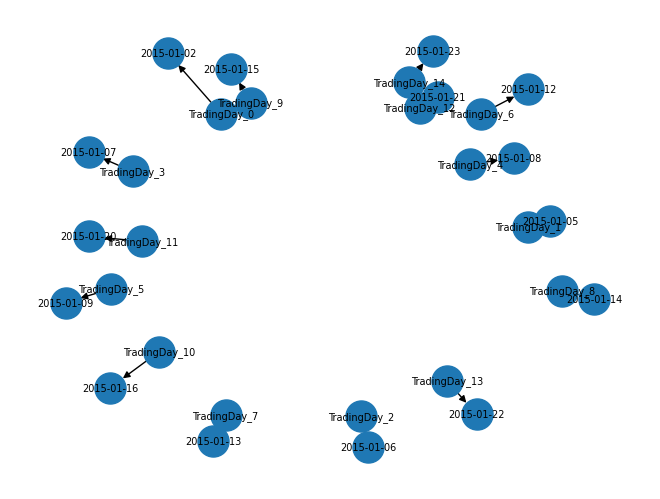

In [14]:
# 13 - visualize graph
sub_nodes = list(G.nodes)[:30]
nx.draw(G.subgraph(sub_nodes), with_labels=True, node_size=500, font_size=7)
plt.show()

In [15]:
# 14 - build tfidf index
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(knowledge_base["document"])

In [16]:
# 15 - retrieve documents
def retrieve_tfidf(query, k=3):
    query_vector = tfidf.transform([query])
    scores = cosine_similarity(query_vector, tfidf_matrix).flatten()
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), documents[i]) for i in indices]

In [17]:
# 16 - test retrieval
for record_id, score, document in retrieve_tfidf("stock with high closing price and trading volume", 3):
    print(f"ID: {record_id} | Score: {score:.4f}\n{document}\n")

ID: 858 | Score: 0.1287
Stock on 2018-05-31: Open 54.1, High 55.5, Low 53.9, Close 55.0, Volume 3968362.

ID: 1008 | Score: 0.1271
Stock on 2019-01-04: Open 52.13, High 54.0, Low 51.84, Close 53.9, Volume 2301428.

ID: 1309 | Score: 0.1270
Stock on 2020-03-17: Open 54.53, High 56.3, Low 52.46, Close 55.9, Volume 4159686.



In [18]:
# 18 - create embeddings
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(documents, show_progress_bar=True, normalize_embeddings=True)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

In [19]:
# 19 - semantic retrieval
def retrieve_semantic(query, k=3):
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = embeddings @ query_embedding[0]
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), documents[i]) for i in indices]

In [20]:
# 20 - test semantic retrieval
for record_id, score, document in retrieve_semantic("What was the stock closing price on a particular trading day?", 3):
    print(f"ID: {record_id} | Similarity: {score:.4f}\n{document}\n")

ID: 622 | Similarity: 0.6312
Stock on 2017-06-22: Open 48.84, High 49.03, Low 48.67, Close 48.83, Volume 1009476.

ID: 603 | Similarity: 0.6275
Stock on 2017-05-25: Open 48.95, High 49.79, Low 48.89, Close 49.59, Volume 1954149.

ID: 750 | Similarity: 0.6232
Stock on 2017-12-22: Open 53.5, High 53.59, Low 53.38, Close 53.44, Volume 889446.



In [21]:
# 21 - graph retrieval
def retrieve_graph(attribute, value):
    return [
        (subject, relation, obj)
        for subject, relation, obj in triples
        if relation == attribute and obj.lower() == str(value).lower()
    ]

In [22]:
# 22 - hybrid retrieval
def hybrid_retrieve(query, attribute=None, value=None, k=3):
    semantic_results = retrieve_semantic(query, k)
    graph_results = retrieve_graph(attribute, value) if attribute else []
    return {"documents": semantic_results, "triples": graph_results[:k]}

In [23]:
# 23 - test hybrid retrieval
results = hybrid_retrieve(
    "stock closing price",
    attribute="has_close",
    value=str(df.iloc[-1]["Close"]),
    k=3
)
print("Retrieved documents:")
for item in results["documents"]:
    print(item)
print("\nRetrieved graph triples:")
print(results["triples"])

Retrieved documents:
(1508, 0.5898245573043823, 'Stock on 2020-12-29: Open 89.36, High 89.42, Low 87.76, Close 87.89, Volume 986287.')
(622, 0.5885858535766602, 'Stock on 2017-06-22: Open 48.84, High 49.03, Low 48.67, Close 48.83, Volume 1009476.')
(1119, 0.5877031087875366, 'Stock on 2019-06-14: Open 54.49, High 54.74, Low 54.07, Close 54.32, Volume 1229304.')

Retrieved graph triples:
[('TradingDay_2515', 'has_close', '189.3')]


In [24]:
# 24 - test questions
test_questions = [
    "What is the stock opening price?",
    "What is the highest stock price?",
    "What is the lowest stock price?",
    "What is the closing price?",
    "What was the trading volume?",
    "Find a day with a high closing price.",
    "Find a day with a low closing price.",
    "What happened to the stock price over time?",
    "Which day had the highest trading volume?",
    "Show stock information for a particular date."
]

In [25]:
# 25 - evaluate retrieval samples
for question in test_questions:
    print("\nQuestion:", question)
    for record_id, score, document in retrieve_semantic(question, 3):
        print(f"ID={record_id}, score={score:.3f}: {document}")


Question: What is the stock opening price?
ID=931, score=0.693: Stock on 2018-09-13: Open 58.99, High 59.39, Low 58.46, Close 59.11, Volume 2003418.
ID=1256, score=0.692: Stock on 2019-12-30: Open 67.84, High 67.85, Low 66.89, Close 66.99, Volume 1000592.
ID=781, score=0.691: Stock on 2018-02-08: Open 52.99, High 53.2, Low 50.24, Close 50.39, Volume 3339601.

Question: What is the highest stock price?
ID=1256, score=0.600: Stock on 2019-12-30: Open 67.84, High 67.85, Low 66.89, Close 66.99, Volume 1000592.
ID=447, score=0.597: Stock on 2016-10-11: Open 40.71, High 40.99, Low 40.37, Close 40.48, Volume 1721575.
ID=480, score=0.595: Stock on 2016-11-28: Open 38.92, High 39.99, Low 38.91, Close 39.29, Volume 2575432.

Question: What is the lowest stock price?
ID=616, score=0.625: Stock on 2017-06-14: Open 48.78, High 48.99, Low 47.98, Close 48.4, Volume 1505486.
ID=379, score=0.624: Stock on 2016-07-06: Open 34.99, High 35.65, Low 34.95, Close 35.45, Volume 1445126.
ID=280, score=0.619: 